## 扇入

--> [下游节点触发] 胜利者是: Model A
--> 采纳的回答: 来自 Model A 的回答


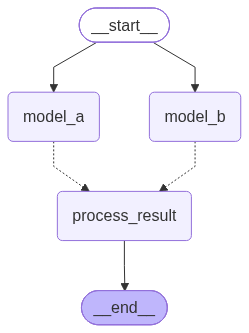

In [ ]:
from typing import Optional, Annotated
from pydantic import BaseModel
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command

# 自定义合并策略：如果已经有值了，保留旧值（即第一名），否则用新值
def take_first(existing: Optional[str], new_value: Optional[str]) -> Optional[str]:
    return existing if existing is not None else new_value

def take_first_bool(existing: bool, new_value: bool) -> bool:
    return existing or new_value

# 1. 状态定义：使用 Annotated 指定 Reducer 解决并发写入冲突
class RaceState(BaseModel):
    prompt: str
    fastest_response: Annotated[Optional[str], take_first] = None
    winner: Annotated[Optional[str], take_first] = None
    is_done: Annotated[bool, take_first_bool] = False

# 2. 模型 A 节点（模拟延迟 1 秒）
def model_a_node(state: RaceState) -> Command:
    # 如果已经有其他模型先完成了，直接放弃处理，终止该分支
    if state.is_done:
        return Command(goto=END)
        
    # 模拟 API 耗时
    import time
    time.sleep(1)
    
    # 抢先完成：更新状态，并用 goto 强制冲向下游节点
    return Command(
        update={
            "fastest_response": "来自 Model A 的回答",
            "winner": "Model A",
            "is_done": True  # 抢占胜利锁
        },
        goto="process_result" # 抢先触发下游节点！
    )

# 3. 模型 B 节点（模拟延迟 2 秒，较慢）
def model_b_node(state: RaceState) -> Command:
    if state.is_done:
        return Command(goto=END)
        
    import time
    time.sleep(2)
    
    return Command(
        update={
            "fastest_response": "来自 Model B 的回答",
            "winner": "Model B",
            "is_done": True
        },
        goto="process_result"
    )

# 4. 下游汇总处理节点
def process_result_node(state: RaceState) -> dict:
    print(f"--> [下游节点触发] 胜利者是: {state.winner}")
    print(f"--> 采纳的回答: {state.fastest_response}")
    return {}

# 5. 构建图结构
builder = StateGraph(RaceState)

builder.add_node("model_a", model_a_node, destinations=("process_result",END))
builder.add_node("model_b", model_b_node, destinations=("process_result",END))
builder.add_node("process_result", process_result_node)

# 从 START 同时开启两条并行分支（Fan-out）
builder.add_edge(START, "model_a")
builder.add_edge(START, "model_b")
builder.add_edge("process_result", END)

app = builder.compile()

# ================= 测试运行 =================
if __name__ == "__main__":
    result = app.invoke({"prompt": "请写一首关于秋天的诗"})
from IPython.display import display,Image
display(Image(app.get_graph().draw_mermaid_png()))    

In [6]:
import json
from typing import Annotated, TypedDict
from langchain_core.tools import tool
from langchain_core.messages import BaseMessage, SystemMessage, ToolMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_deepseek import ChatDeepSeek
from langgraph.prebuilt import ToolNode
import os
from dotenv import load_dotenv
load_dotenv(override=True)
from langchain_community.tools.tavily_search import TavilySearchResults
model = ChatDeepSeek(
    model='deepseek-v4-flash',
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)
# 1. 定义简易工具
@tool
def search_web(query: str) -> str:
    """仅用于查询北京地区的模拟天气数据。如果是其他城市，请勿调用此工具。"""
    # 模拟搜索结果
    if "天气" in query and "北京" in query:
        return "北京今日天气：晴朗，18℃ ~ 25℃，微风。"
    return "未搜索到相关信息。"
# 定义 Tavily 工具
tavily_tool = TavilySearchResults(max_results=2)
@tool
def read_local_file(file_path: str) -> str:
    """读取指定路径的本地文本文件内容。
    
    Args:
        file_path: 文件相较于工作区的相对路径或绝对路径。
    """
    if not os.path.exists(file_path):
        return f"错误：文件 '{file_path}' 不存在。"
    
    try:
        with open(file_path, "r", encoding="utf-8") as f:
            content = f.read()
        return content
    except Exception as e:
        return f"读取文件失败: {str(e)}"

@tool
def write_local_file(file_path: str, content: str) -> str:
    """将文本内容写入到本地文件中，如果文件已存在会覆盖内容。
    
    Args:
        file_path: 要保存的文件路径。
        content: 需要写入文件的完整文本内容。
    """
    try:
        # 自动创建不存在的父级目录
        os.makedirs(os.path.dirname(file_path), exist_ok=True) if os.path.dirname(file_path) else None
        
        with open(file_path, "w", encoding="utf-8") as f:
            f.write(content)
        return f"成功写入文件 '{file_path}'。"
    except Exception as e:
        return f"写入文件失败: {str(e)}"
tools = [search_web,tavily_tool, read_local_file, write_local_file]
# 将工具绑定到配置好的 DeepSeek 模型上
llm_with_tools = model.bind_tools(tools)

# 2. 定义状态 Schema（使用 add_messages 自动累加历史对话）
class AgentState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

# 3. 定义核心 LLM 节点（Reasoning）
def agent_node(state: AgentState):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}


# 4. 定义工具执行节点（Action）
# def tool_node(state: AgentState):
#     latest_message = state["messages"][-1]
#     tool_messages = []
    
#     # 遍历 LLM 生成的所有 tool_calls，依次执行工具
#     for tool_call in latest_message.tool_calls:
#         if tool_call["name"] == "search_web":
#             observation = search_web.invoke(tool_call["args"])
#             # 构建 ToolMessage 返回给大模型
#             tool_messages.append(
#                 ToolMessage(
#                     content=str(observation),
#                     tool_call_id=tool_call["id"]
#                 )
#             )
            
#     return {"messages": tool_messages}
tool_node = ToolNode(tools)


# 5. 定义条件路由函数（决定是否继续 Loop）
def should_continue(state: AgentState) -> str:
    last_message = state["messages"][-1]
    # 判断 LLM 是否输出了 tool_calls：如果有，说明需要调用工具；如果没有，说明已拿到最终答案
    if last_message.tool_calls:
        return "tools"
    return END

# 6. 构建静态图 (Static ReAct Cycle)
builder = StateGraph(AgentState)

builder.add_node("agent", agent_node)
builder.add_node("tools", tool_node)

builder.add_edge(START, "agent")

# 静态关键点：显式声明分支拓扑路由
builder.add_conditional_edges(
    "agent",
    should_continue,
    {
        "tools": "tools",  # 如果路由返回 "tools"，去工具节点
        END: END           # 如果路由返回 END，结束循环
    }
)

# 工具执行完后，必须把 ToolMessage 传回给 agent 节点，形成闭环 Loop
builder.add_edge("tools", "agent")

app = builder.compile()

# ================= 运行测试 =================
if __name__ == "__main__":
    inputs = {"messages": [("user", "hello_agents/test.py 这个文件的内容是什么？请帮我读取并打印出来。")]}
    
    for chunk in app.stream(inputs, stream_mode="values"):
        latest_msg = chunk["messages"][-1]
        print(f"\n[{latest_msg.type.upper()}]: {latest_msg.content}")
        if hasattr(latest_msg, "tool_calls") and latest_msg.tool_calls:
            print(f"--> 发起工具调用: {latest_msg.tool_calls}")


[HUMAN]: hello_agents/test.py 这个文件的内容是什么？请帮我读取并打印出来。

[AI]: 我来帮你读取这个文件的内容。
--> 发起工具调用: [{'name': 'read_local_file', 'args': {'file_path': 'hello_agents/test.py'}, 'id': 'call_00_R7Sjhx7dmpK0bHwrwTEk4900', 'type': 'tool_call'}]

[TOOL]: 错误：文件 'hello_agents/test.py' 不存在。

[AI]: 这个文件路径不存在。让我先确认一下工作区中是否有其他相关文件。
--> 发起工具调用: [{'name': 'search_web', 'args': {'query': 'hello_agents test.py file'}, 'id': 'call_00_ro1nzOGzKKXAnqFJp34C3325', 'type': 'tool_call'}, {'name': 'read_local_file', 'args': {'file_path': 'test.py'}, 'id': 'call_01_tUar8rejSYaSSNwggP834470', 'type': 'tool_call'}]

[TOOL]: import time
from typing import List, Annotated, Literal
import operator
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END

# 1. 定义更丰富的工单状态 Schema
class TicketState(BaseModel):
    ticket_id: str                      # 工单ID
    raw_user_input: str                 # 用户原始输入
    is_valid: bool = True               # 输入是否合法
    category: str = "未分类"             # 工单类别：技术

In [8]:
from langchain_core.messages import SystemMessage, AIMessage, HumanMessage
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
from rich import print as rprint
import os
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv
load_dotenv(override=True)
# 从.env文件中加载环境变量
model = ChatDeepSeek(
    model='deepseek-v4-flash',
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)
# 使用字典格式构建消息
response = model.invoke([HumanMessage("2 + 3 * 2 = ？")])
# 打印响应
print(type(response))
# <class 'langchain_core.messages.ai.AIMessage'>
rprint(response)

<class 'langchain_core.messages.ai.AIMessage'>


AIMessage(
    content='好的，我们先一步步来看这个数学表达式：**2 + 3 * 2**。  
\n\n按照数学中的运算优先级（先乘除后加减），我们应先计算乘法部分：  \n3 × 2 = 6  \n\n然后再进行加法：  \n2 + 6 = 8 
\n\n所以，结果是：  \n**8**',
    additional_kwargs={'refusal': None},
    response_metadata={
        'token_usage': {
            'completion_tokens': 68,
            'prompt_tokens': 14,
            'total_tokens': 82,
            'completion_tokens_details': None,
            'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
            'prompt_cache_hit_tokens': 0,
            'prompt_cache_miss_tokens': 14
        },
        'model_provider': 'deepseek',
        'model_name': 'deepseek-v4-flash',
        'system_fingerprint': 'a26a7955944dc5c60445bff77fac9c8e',
        'id': 'fed375d4-6791-41a1-ae90-c2226e480666',
        'finish_reason': 'stop',
        'logprobs': None
    },
    id='lc_run--01a060d6-1a89-75e1-8423-1c09fbcd7f34-0',
    tool_calls=[],
    invalid_tool_calls=[],
    usage_metadata={
        'input_tokens': 14,
        'output_tokens': 68,
        'total_tokens': 82,
        'input_token_details': {'cache_read': 0},
        'output_token_details': {}
    }
)

In [3]:
# lesson2.py —— 第一个会对话的 agent（带记忆）
import os
from dotenv import load_dotenv
from langchain_deepseek import ChatDeepSeek
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage

from dotenv import load_dotenv
load_dotenv(override=True)                   # 读当前目录的 .env
model = ChatDeepSeek(
    model='deepseek-v4-flash',
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

# 1. 节点：调用大模型
def chatbot(state: MessagesState):
    return {"messages": [model.invoke(state["messages"])]}

# 2. 建图（和第一课几乎一样，State 换成 MessagesState）
builder = StateGraph(MessagesState)
builder.add_node("chatbot", chatbot)
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

# 3. 编译时挂上"记忆"
graph = builder.compile(checkpointer=InMemorySaver())

# 4. 多轮对话：同一个 thread_id = 同一个人
config = {"configurable": {"thread_id": "1"}}

r1 = graph.invoke({"messages": [HumanMessage("你好，我叫小明")]}, config)
print(r1["messages"][-1].content)
print(r1["messages"])

r2 = graph.invoke({"messages": [HumanMessage("我叫什么名字？")]}, config)
print(r2["messages"][-1].content)
# 打印message
print(r2["messages"])

你好，小明！很高兴认识你！🎉 我是DeepSeek，一个乐于助人的AI助手，随时准备为你解答问题、提供建议或者陪你聊天。有什么我可以帮你的吗？无论是学习、工作、生活中的疑问，还是想聊聊兴趣爱好，我都在这里！😊
[HumanMessage(content='你好，我叫小明', additional_kwargs={}, response_metadata={}, id='d00d7414-3196-4ffe-86f7-f1f34bceba36'), AIMessage(content='你好，小明！很高兴认识你！🎉 我是DeepSeek，一个乐于助人的AI助手，随时准备为你解答问题、提供建议或者陪你聊天。有什么我可以帮你的吗？无论是学习、工作、生活中的疑问，还是想聊聊兴趣爱好，我都在这里！😊', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 60, 'prompt_tokens': 8, 'total_tokens': 68, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 8}, 'model_provider': 'deepseek', 'model_name': 'deepseek-v4-flash', 'system_fingerprint': 'a26a7955944dc5c60445bff77fac9c8e', 'id': 'ec1201b5-c53a-479a-965b-5aa8006e740d', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a0653b-157a-79f3-a676-ba380c5d9e50-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'outpu